## Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
df.shape

(2200, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [5]:
df.describe(include='all')

,N,P,K,temperature,humidity,ph,rainfall,label
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rice
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,NaN
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,NaN
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,NaN
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,NaN
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,NaN
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,NaN


In [6]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='str')

In [9]:
df.dtypes

N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

## EDA

In [10]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

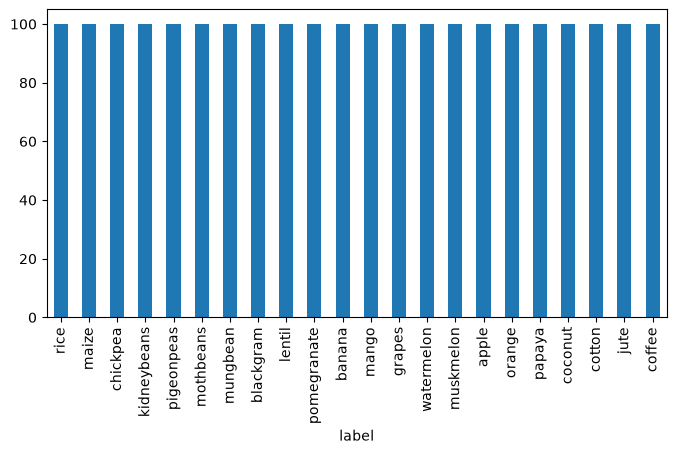

In [11]:
df['label'].value_counts().plot(kind='bar', figsize=(8,4))
plt.xticks(rotation=90)
plt.show()

In [12]:
# Check class imbalance
df['label'].value_counts(normalize=True) * 100

label
rice           4.545455
maize          4.545455
chickpea       4.545455
kidneybeans    4.545455
pigeonpeas     4.545455
mothbeans      4.545455
mungbean       4.545455
blackgram      4.545455
lentil         4.545455
pomegranate    4.545455
banana         4.545455
mango          4.545455
grapes         4.545455
watermelon     4.545455
muskmelon      4.545455
apple          4.545455
orange         4.545455
papaya         4.545455
coconut        4.545455
cotton         4.545455
jute           4.545455
coffee         4.545455
Name: proportion, dtype: float64

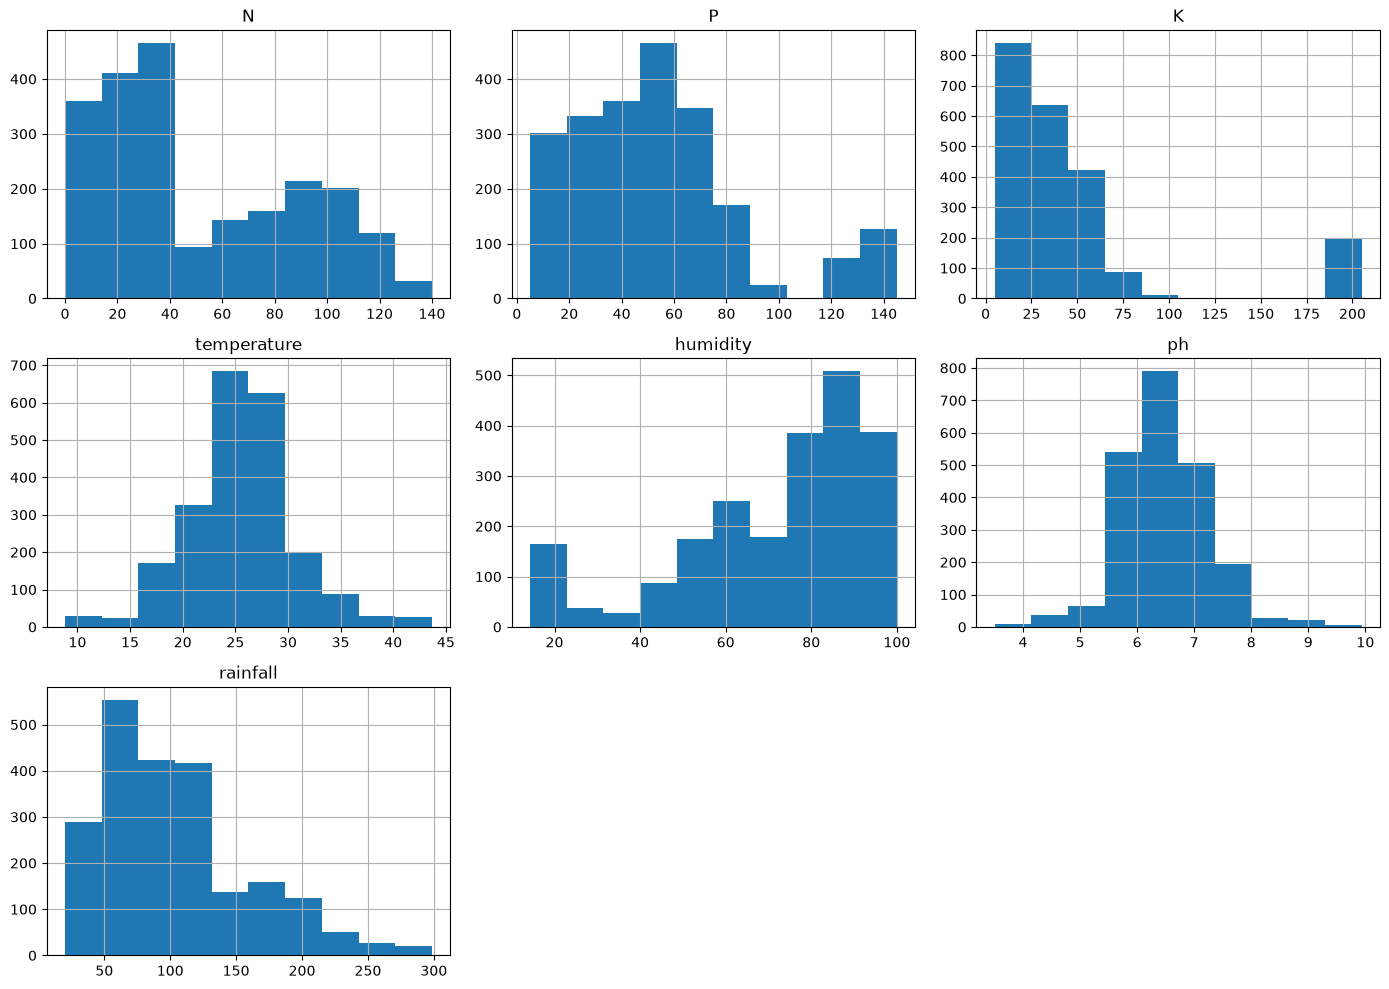

In [13]:
# Numerical Features
df.hist(figsize=(14,10))
plt.tight_layout()
plt.show()

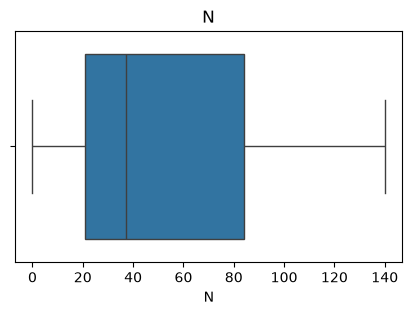

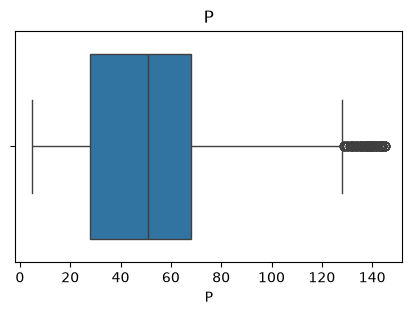

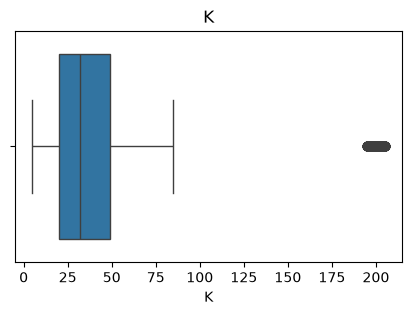

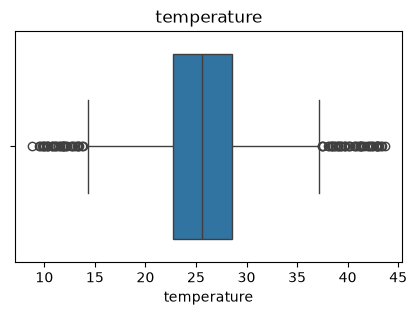

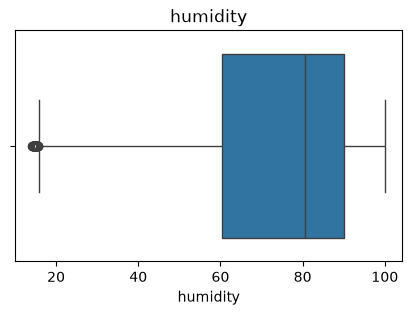

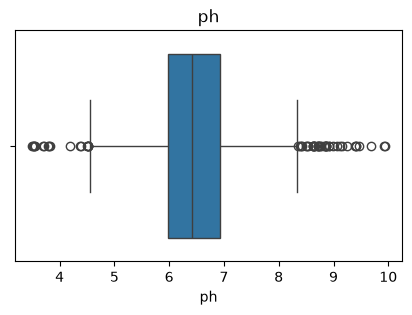

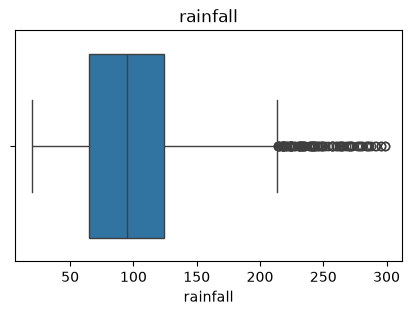

In [14]:
# Boxplots
for col in df.columns[:-1]:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

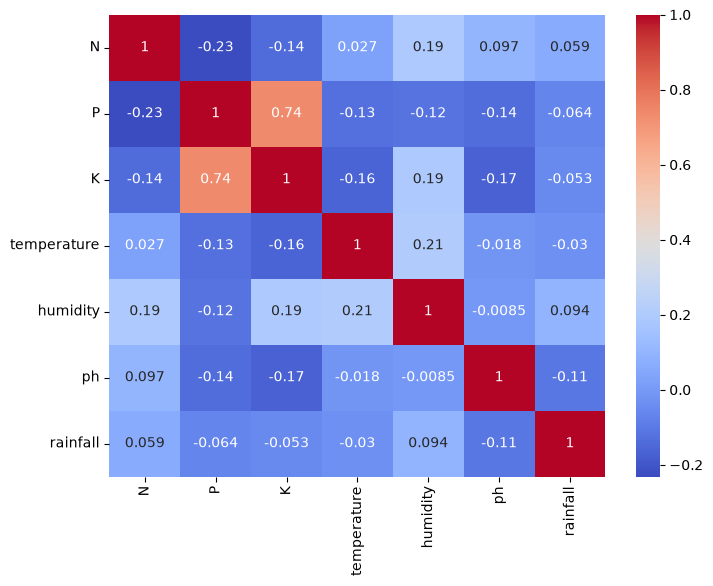

In [15]:
# Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

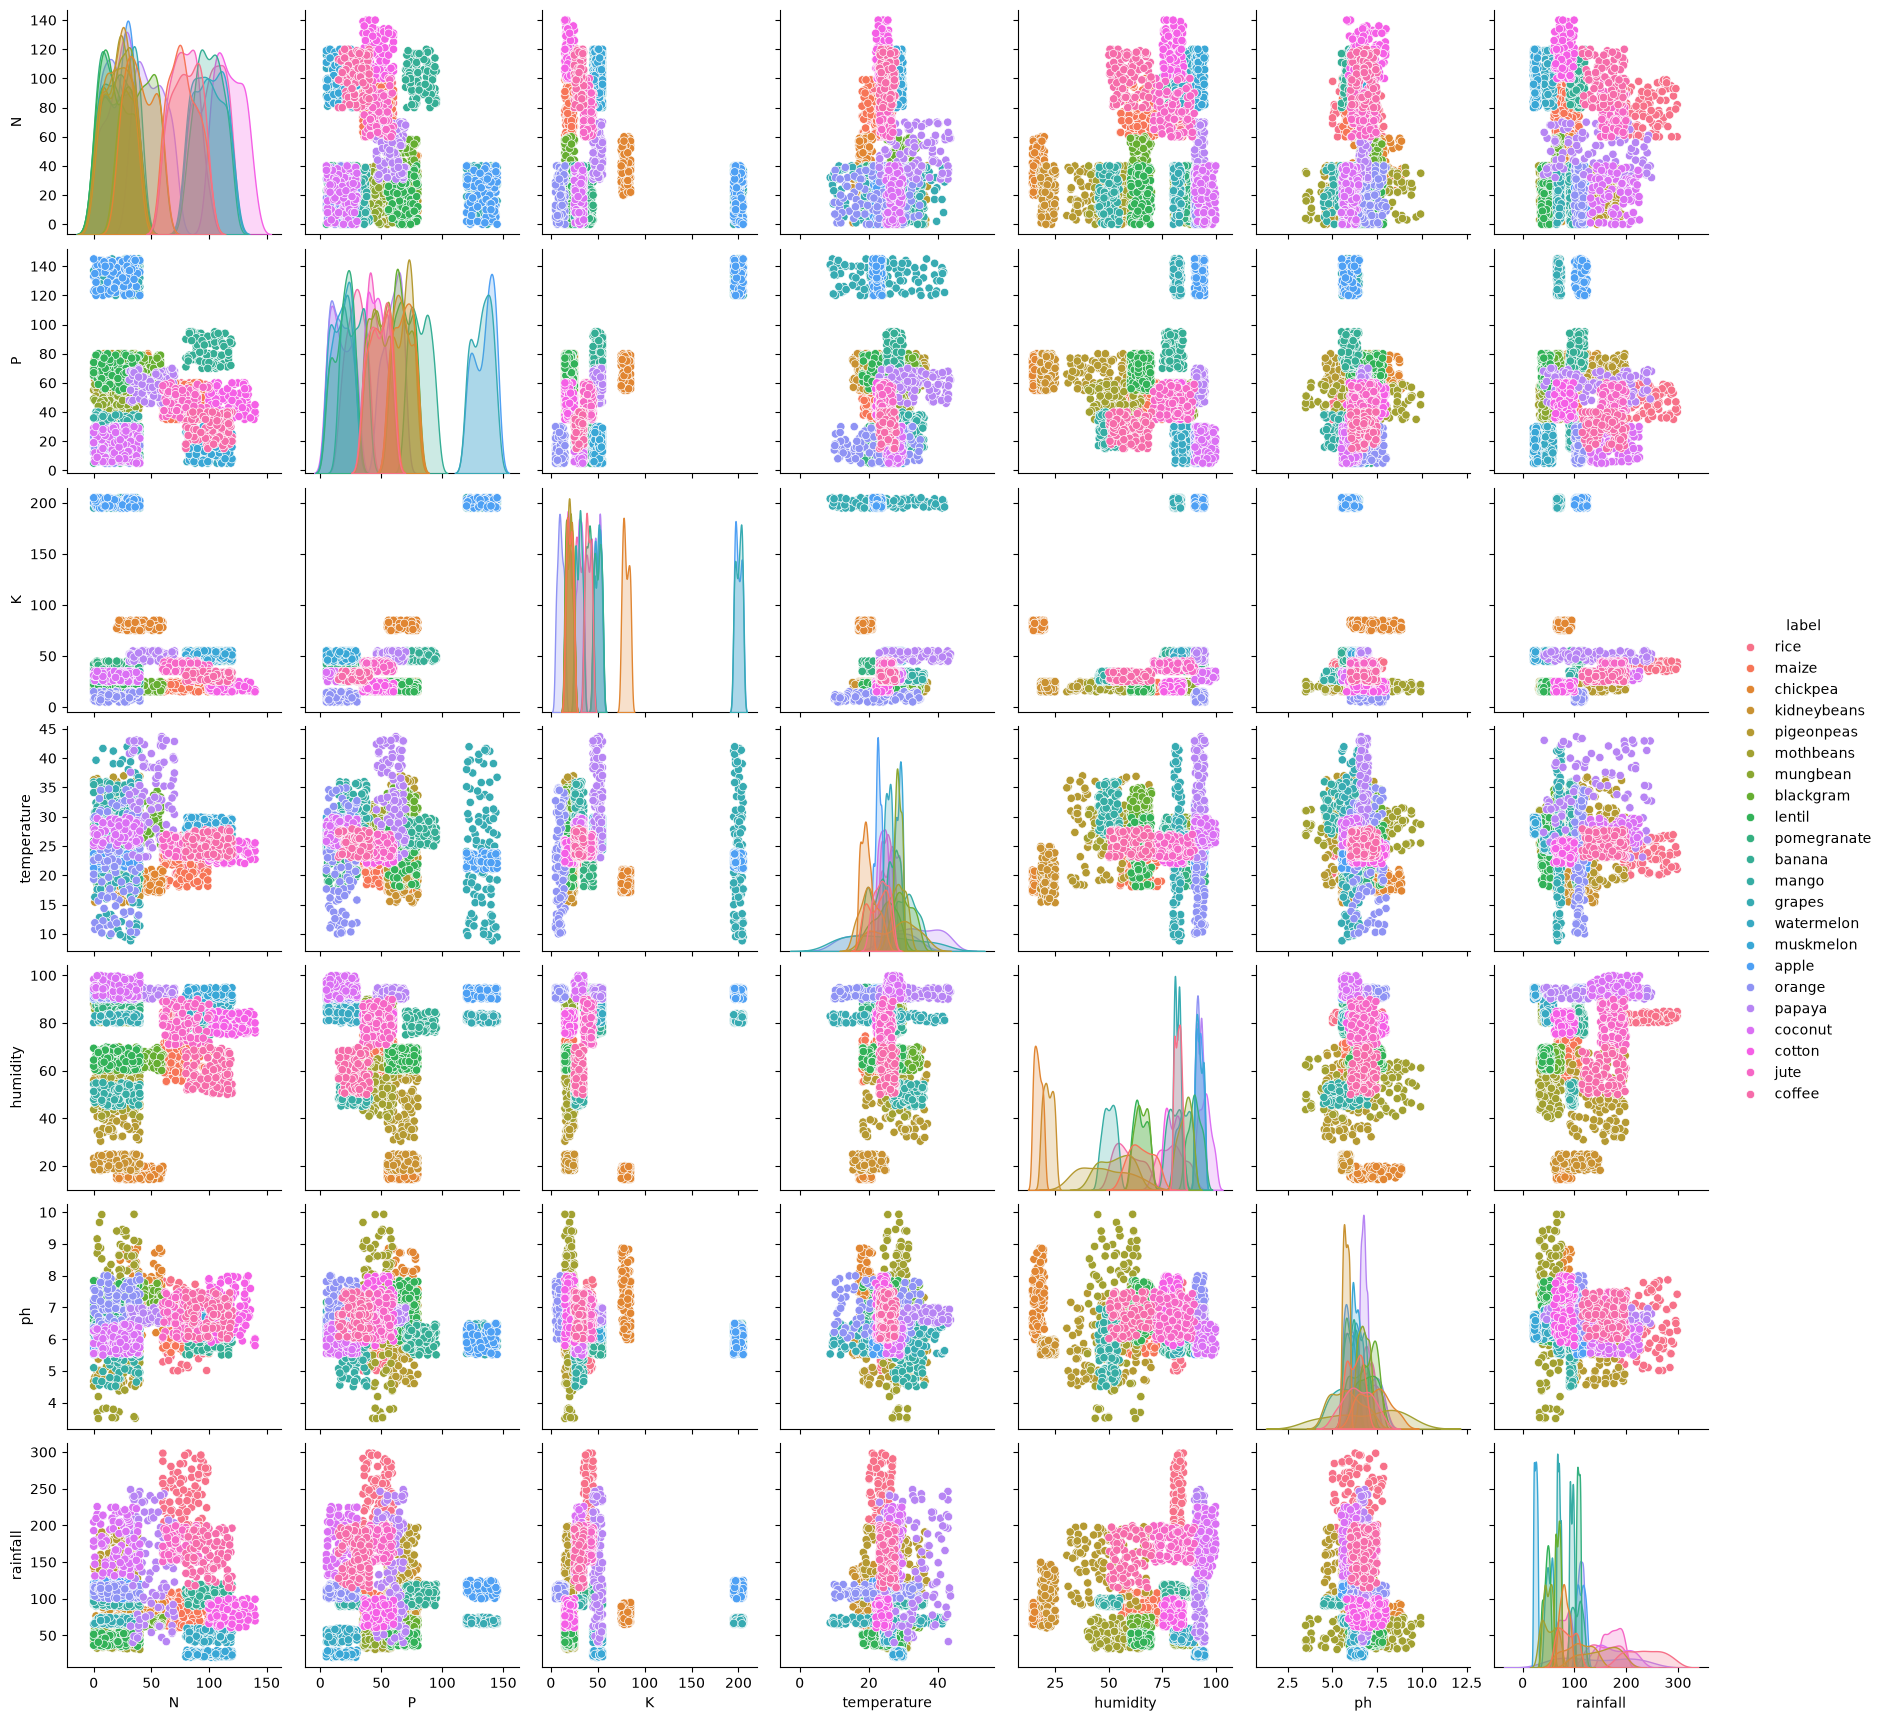

In [16]:
# Pairplot
sns.pairplot(df, hue='label')

## Data Preprocessing

In [17]:
# Features and target
X = df.drop('label', axis=1)
y = df['label']

In [18]:
# Encode labels
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [19]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
import time
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

In [21]:
# Create pipeline
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True))
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(random_state=42))
    ]),

    "XGBoost": Pipeline([
        ("model", XGBClassifier(
            random_state=42,
            eval_metric="mlogloss"
        ))
    ])
}

In [22]:
# Model Evaluation Function
def evaluate_models(models, X_train, X_test, y_train, y_test):

    results = []
    trained_models = {}
    for name, model in models.items():
        train_start = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - train_start

        pred_start = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - pred_start

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)

            roc_auc = roc_auc_score(
                y_test,
                y_prob,
                multi_class="ovr",
                average="weighted"
            )
        else:
            roc_auc = np.nan

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average="weighted")
        recall = recall_score(y_test, y_pred, average="weighted")
        f1 = f1_score(y_test, y_pred, average="weighted")

        trained_models[name] = model

        results.append({
            "Model": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC-AUC": roc_auc,
            "Train Time (s)": train_time,
            "Prediction Time (s)": pred_time
        })

        print("="*70)
        print(name)
        print("="*70)

        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))

    results = pd.DataFrame(results)

    results = results.sort_values(
        by=["Accuracy", "Prediction Time (s)"],
        ascending=[False, True]
    )

    return results, trained_models

In [23]:
# Train all Models
results, trained_models = evaluate_models(
    models,
    X_train,
    X_test,
    y_train,
    y_test
)

results

Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       0.95      1.00      0.98        20
           3       1.00      1.00      1.00        20
           4       0.95      1.00      0.98        20
           5       1.00      1.00      1.00        20
           6       0.95      1.00      0.98        20
           7       1.00      1.00      1.00        20
           8       0.83      1.00      0.91        20
           9       1.00      1.00      1.00        20
          10       0.94      0.85      0.89        20
          11       1.00      0.95      0.97        20
          12       0.95      1.00      0.98        20
          13       0.90      0.90      0.90        20
          14       1.00      1.00      1.00        20
          15       1.00      1.00      1.00        20
          16       1.00      0.95      0.97        20
       

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Train Time (s),Prediction Time (s)
4,Random Forest,0.995455,0.995671,0.995455,0.995452,0.999995,0.873868,0.022698
5,XGBoost,0.993182,0.993506,0.993182,0.993116,0.999924,1.211443,0.015621
2,SVM,0.984091,0.985610,0.984091,0.984038,1.000000,0.556822,0.100581
3,Decision Tree,0.979545,0.980598,0.979545,0.979423,0.989286,0.030737,0.002430
1,KNN,0.979545,0.980356,0.979545,0.979283,0.998723,0.010738,0.013184
0,Logistic Regression,0.972727,0.974022,0.972727,0.972464,0.999811,0.165802,0.003261


In [24]:
# Cross Validation
def cross_validation(models, X, y):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    scores = []
    for name, model in models.items():
        accuracy = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )
        scores.append({

            "Model": name,
            "Mean Accuracy": accuracy.mean(),
            "Std": accuracy.std()

        })

    return pd.DataFrame(scores).sort_values(
        by="Mean Accuracy",
        ascending=False
    )

In [25]:
cv_results = cross_validation(models, X, y)
cv_results

,Model,Mean Accuracy,Std
4,Random Forest,0.995455,0.003214
5,XGBoost,0.992727,0.003015
3,Decision Tree,0.987727,0.006833
2,SVM,0.983636,0.004407
1,KNN,0.971364,0.006833
0,Logistic Regression,0.970909,0.002227


In [26]:
# Hyperparameter Tunning
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators":[100,200,300],
    "model__max_depth":[None,10,20],
    "model__min_samples_split":[2,5],
    "model__min_samples_leaf":[1,2]
}

In [27]:
grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [28]:
print(grid.best_params_)
print(grid.best_score_)

{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}
0.9960227272727271


In [29]:
# Best Model
best_pipeline = grid.best_estimator_

In [30]:
# Test Tunned Models
y_pred = best_pipeline.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

y_prob = best_pipeline.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print("Accuracy :",accuracy)
print("Precision :",precision)
print("Recall :",recall)
print("F1 :",f1)
print("ROC AUC :",roc_auc)

print(classification_report(y_test,y_pred))

print(confusion_matrix(y_test,y_pred))

Accuracy : 0.9954545454545455
Precision : 0.9956709956709956
Recall : 0.9954545454545455
F1 : 0.9954517027687759
ROC AUC : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      0.95      0.97        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       0.95      1.00      0.98        20
           9       1.00      1.00      1.00        20
          10       1.00      1.00      1.00        20
          11       0.95      1.00      0.98        20
          12       1.00      1.00      1.00        20
          13       1.00      1.00      1.00        20
          14       1.00      1.00      1.00        20
        

In [31]:
joblib.dump(
    best_pipeline, "crop_pipeline.pkl"
)

['crop_pipeline.pkl']

In [32]:
joblib.dump(
    encoder, "crop_label_encoder.pkl"
)

['crop_label_encoder.pkl']

In [33]:
pipeline = joblib.load("crop_pipeline.pkl")
encoder = joblib.load("crop_label_encoder.pkl")

In [34]:
sample = [[
    90,
    82,
    43,
    30.8,
    82.0,
    10.5,
    202.9
]]

prediction = pipeline.predict(sample)
crop = encoder.inverse_transform(prediction)
print(crop[0])

banana
